# ENVS 117 Week 3 Thursday: Demo Code
**Spatial Data Models and Formats**

Run the download cell at the very start of class (about 43 MB). Textbook: Wu Ch 15, with previews of 16 and 17.

## Setup: get the data

In [4]:
from pathlib import Path
from urllib.request import urlretrieve

BASE = ("https://github.com/opengeos/"
        "datasets/releases/download/")
files = ["us/us_counties.geojson",
         "us/cities.csv",
         "raster/dem_90m.tif"]

Path("data").mkdir(exist_ok=True)
for f in files:
    name = f.split("/")[-1]
    if not Path("data/" + name).exists():      # skip if already downloaded
        urlretrieve(BASE + f, "data/" + name)
        print("downloaded", name)
    else:
        print("already have", name)

already have us_counties.geojson
already have cities.csv
already have dem_90m.tif


In [5]:
import os
import math
import pandas as pd
import geopandas as gpd
import rasterio

## Part 1. File formats
### One shapefile is really five files

In [6]:
counties = gpd.read_file("data/us_counties.geojson")
ca = counties[counties["STATE"] == "06"]

ca.to_file("data/ca_counties.shp")
ca.to_file("data/ca_counties.gpkg")

print("Shapefile parts:", sorted(f for f in os.listdir("data") if f.startswith("ca_counties.") and not f.endswith(".gpkg")))
print("GeoPackage size:", round(os.path.getsize("data/ca_counties.gpkg") / 1e6, 2), "MB")

Shapefile parts: ['ca_counties.cpg', 'ca_counties.dbf', 'ca_counties.prj', 'ca_counties.shp', 'ca_counties.shx']
GeoPackage size: 0.74 MB


### What a GeoTIFF records

In [7]:
with rasterio.open("data/dem_90m.tif") as src:
    print("Size:      ", src.width, "x", src.height)
    print("Bands:     ", src.count)
    print("Resolution:", src.res)
    print("Data type: ", src.dtypes)
    print("NoData:    ", src.nodata)
    print("CRS:       ", src.crs)
    print("Bounds:    ", src.bounds)

Size:       4269 x 3113
Bands:      1
Resolution: (90.0, 89.99579177642138)
Data type:  ('int16',)
NoData:     None
CRS:        EPSG:3857
Bounds:     BoundingBox(left=-13442488.3428, bottom=4388214.6777, right=-13058278.3428, top=4668371.5775)


## Part 2. Coordinate reference systems
### Santa Clara County: one area, three answers

In [8]:
sc = ca[ca["NAME"] == "Santa Clara"]
print(sc.crs)

print("EPSG:4269 (degrees):  ", round(sc.area.iloc[0], 3))      # warning expected
print("EPSG:3310 (Albers):   ", round(sc.to_crs(3310).area.iloc[0] / 1e6), "km2")
print("EPSG:3857 (Mercator): ", round(sc.to_crs(3857).area.iloc[0] / 1e6), "km2")
print("Census land area:     ", round(sc["CENSUSAREA"].iloc[0] * 2.59), "km2")

EPSG:4269
EPSG:4269 (degrees):   0.343
EPSG:3310 (Albers):    3378 km2


/var/folders/zs/4zds_td97pl9hxx9pcf2mt2c0000gn/T/ipykernel_34401/2940449104.py:4: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  print("EPSG:4269 (degrees):  ", round(sc.area.iloc[0], 3))      # warning expected


EPSG:3857 (Mercator):  5338 km2
Census land area:      3341 km2


### set_crs labels; to_crs converts

False
True


<Axes: >

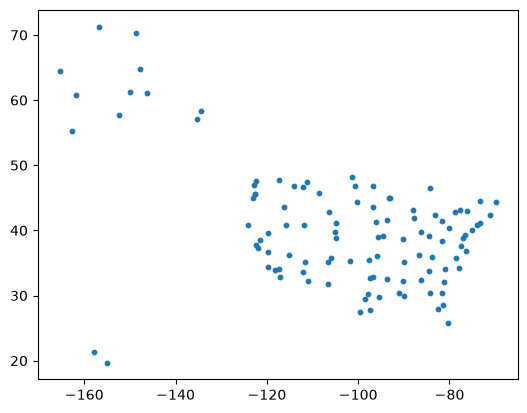

In [15]:
cities = pd.read_csv("data/cities.csv")

pts = gpd.GeoDataFrame(
    cities,
    geometry=gpd.points_from_xy(
        cities["longitude"], cities["latitude"]),
    crs="EPSG:4326")

print(pts.crs == counties.crs)     # False
pts = pts.to_crs(counties.crs)
print(pts.crs == counties.crs)     # True

pts.plot(markersize=10)

In [10]:
# The classic bug: set_crs does NOT move the points
wrong = pts.to_crs(4326).set_crs(3310, allow_override=True)
print("to_crs result:     ", pts.to_crs(3310).geometry.iloc[0])
print("set_crs mislabel:  ", wrong.geometry.iloc[0], " <- still degrees, now labeled meters")

to_crs result:      POINT (249022.11998068242 -429267.18388468586)
set_crs mislabel:   POINT (-117.30002999999999 34.12038)  <- still degrees, now labeled meters


## Part 3. Opening files in Python
### A GeoDataFrame is a table that knows where it is

In [11]:
counties = gpd.read_file("data/us_counties.geojson")

print(counties.shape)
print(counties.crs)
print(counties.geom_type.unique())
ca = counties[counties["STATE"] == "06"]
print(ca.total_bounds)
counties.head()

(3221, 7)
EPSG:4269
<StringArray>
['MultiPolygon']
Length: 1, dtype: str
[-124.409591     32.534156   -114.13442654   42.009518  ]


,GEO_ID,STATE,COUNTY,NAME,LSAD,CENSUSAREA,geometry
0,0500000US01029,01,029,Cleburne,County,560.100,"MULTIPOLYGON (((-85.38872 33.91304, -85.38088 ..."
1,0500000US01031,01,031,Coffee,County,678.972,"MULTIPOLYGON (((-86.03044 31.61894, -86.00408 ..."
2,0500000US01037,01,037,Coosa,County,650.926,"MULTIPOLYGON (((-86.00928 33.10164, -86.00917 ..."
3,0500000US01039,01,039,Covington,County,1030.456,"MULTIPOLYGON (((-86.34851 30.99434, -86.35023 ..."
4,0500000US01041,01,041,Crenshaw,County,608.840,"MULTIPOLYGON (((-86.14699 31.68046, -86.14711 ..."


### Rasterio reads metadata first, pixels when you ask

In [12]:
with rasterio.open("data/dem_90m.tif") as src:
    print(src.crs)
    print(src.res)
    print(src.count)
    print(src.dtypes)
    dem = src.read(1)

print(type(dem), dem.shape)
print(dem.max())

EPSG:3857
(90.0, 89.99579177642138)
1
('int16',)
<class 'numpy.ndarray'> (3113, 4269)
4338


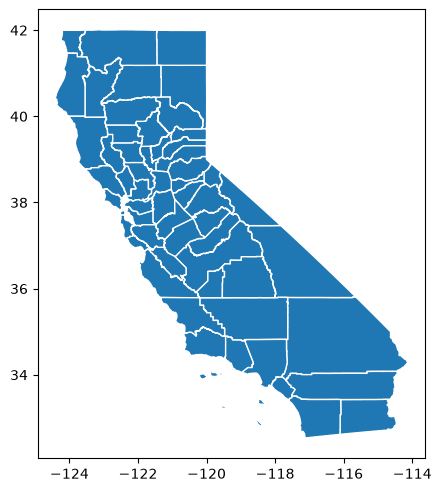

In [13]:
# a quick look
ca.plot(edgecolor="white", figsize=(5, 6));